2.1


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


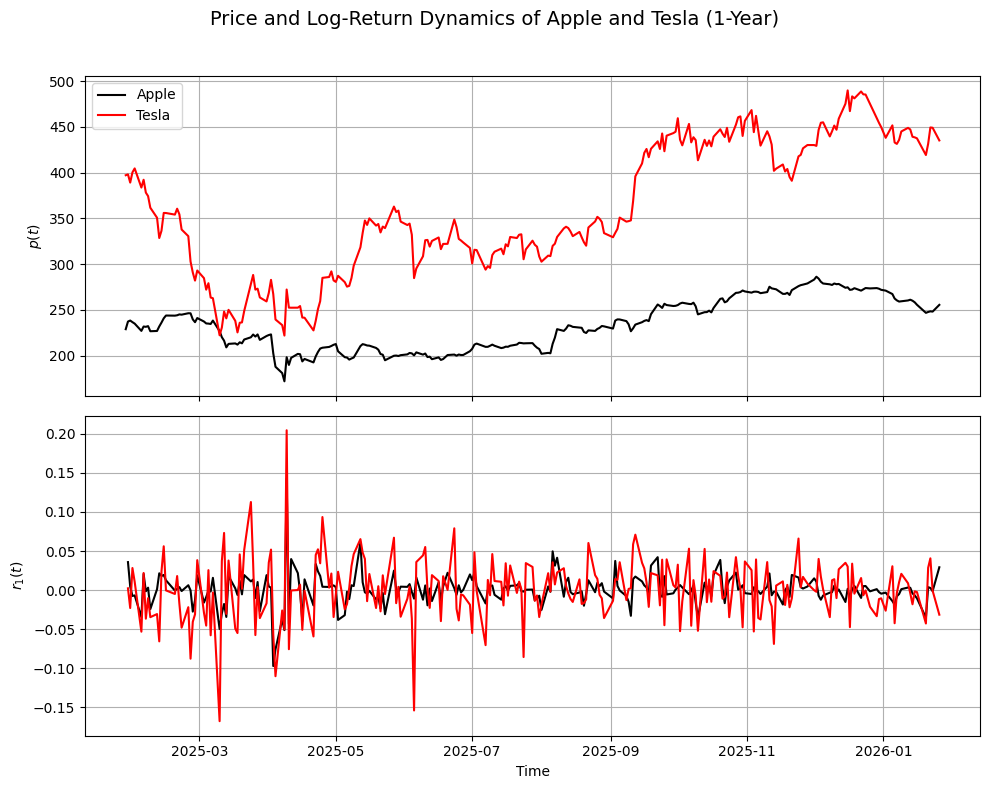

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

tickers = {
    "Apple": "AAPL",
    "Tesla": "TSLA"
}

colors = {
    "Apple": "Black",
    "Tesla": "Red"
}

data = {k: yf.download(v, period="1y") for k, v in tickers.items()}

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(10, 8))

# ---- Figure title ----
fig.suptitle("Price and Log-Return Dynamics of Apple and Tesla (1-Year)", fontsize=14)

for name, df in data.items():
    p = df["Close"]
    r1 = np.log(p / p.shift(1))

    ax1.plot(p.index, p, color=colors[name], label=name)
    ax2.plot(r1.index, r1, color=colors[name], label=name)

ax1.set_ylabel(r"$p(t)$")
ax1.legend()
ax1.grid(True)

ax2.set_ylabel(r"$r_1(t)$")
ax2.set_xlabel("Time")
ax2.grid(True)

plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


Apple excess kurtosis: 12.286
Tesla excess kurtosis: 4.111


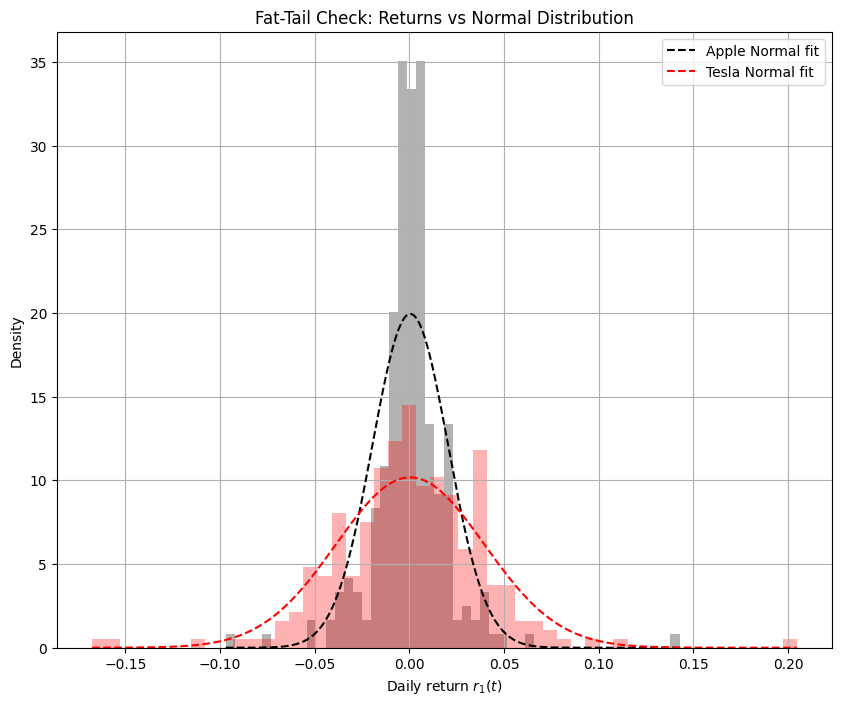

In [ ]:
# Fat-tail check: histogram vs normal distribution + excess kurtosis
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

# Example tickers dictionary

tickers = {
    "Apple": ("AAPL", "Black"),
    "Tesla": ("TSLA", "Red"),
}

plt.figure(figsize=(10, 8))

for name, val in tickers.items():
    # Handle whether value is a tuple (ticker, color) or just a ticker string
    if isinstance(val, tuple):
        ticker, color = val
    else:
        ticker = val
        color = "gray" 

    # Download data
    df = yf.download(ticker, period="1y", progress=False)
    p = df["Close"]
    r = np.log(p / p.shift(1)).dropna()

    # Compute mean, std, excess kurtosis
    mu, sigma = r.mean(), r.std()
    x = np.linspace(r.min(), r.max(), 500)
    gamma = (((r - mu)**4).mean() / sigma**4 - 3).item()  # ensure scalar
    print(f"{name} excess kurtosis: {gamma:.3f}")

    # Plot histogram and normal fit
    plt.hist(r, bins=50, density=True, alpha=0.3, color=color)
    plt.plot(x, norm.pdf(x, mu, sigma), color=color, linestyle="--", label=f"{name} Normal fit")

plt.xlabel(r"Daily return $r_1(t)$")
plt.ylabel("Density")
plt.title("Fat-Tail Check: Returns vs Normal Distribution")
plt.legend()
plt.grid(True) 
plt.show()


[*********************100%***********************]  1 of 1 completed


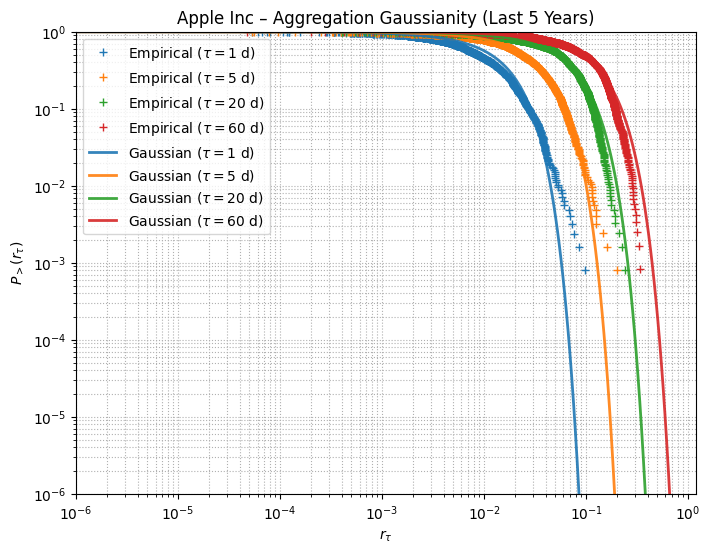

In [ ]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm

# 1. Data
aapl = yf.download("AAPL", period="5y", auto_adjust=True)

prices = aapl['Close'].squeeze()
returns = np.log(prices).diff().dropna()


# 2. Helper functions
def aggregate_returns(r, tau):
    return r.rolling(tau).sum().dropna()

def ccdf(data):
    x = np.sort(np.abs(data))
    y = 1.0 - np.arange(1, len(x) + 1) / len(x)
    return x, y

# 3. Parameters

taus = [1, 5, 20, 60]
colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red']

sigma1 = returns.std()
xg = np.logspace(-6, 1, 400)


# 4. Plot

plt.figure(figsize=(8, 6))

# Empirical CCDFs
for tau, c in zip(taus, colors):
    r_tau = aggregate_returns(returns, tau)
    x, y = ccdf(r_tau)
    plt.loglog(
        x, y,
        marker='+',
        linestyle='None',
        color=c,
        label=fr'Empirical ($\tau={tau}$ d)'
    )

# Gaussian benchmarks (with legend labels)
for tau, c in zip(taus, colors):
    sigma_tau = np.sqrt(tau) * sigma1
    yg = 2 * (1 - norm.cdf(xg / sigma_tau))
    plt.loglog(
        xg, yg,
        color=c,
        linewidth=2,
        alpha=0.9,
        label=fr'Gaussian ($\tau={tau}$ d)'
    )


# 5. Axis formatting (correct orientation)

plt.xscale('log')
plt.yscale('log')

plt.xlim(1e-6, 1.2)
plt.ylim(1e-6, 1)

plt.xlabel(r'$r_\tau$')
plt.ylabel(r'$P_{>}(r_\tau)$')
plt.title("Apple Inc – Aggregation Gaussianity (Last 5 Years)")

plt.legend()
plt.grid(True, which='both', linestyle=':')

plt.show()


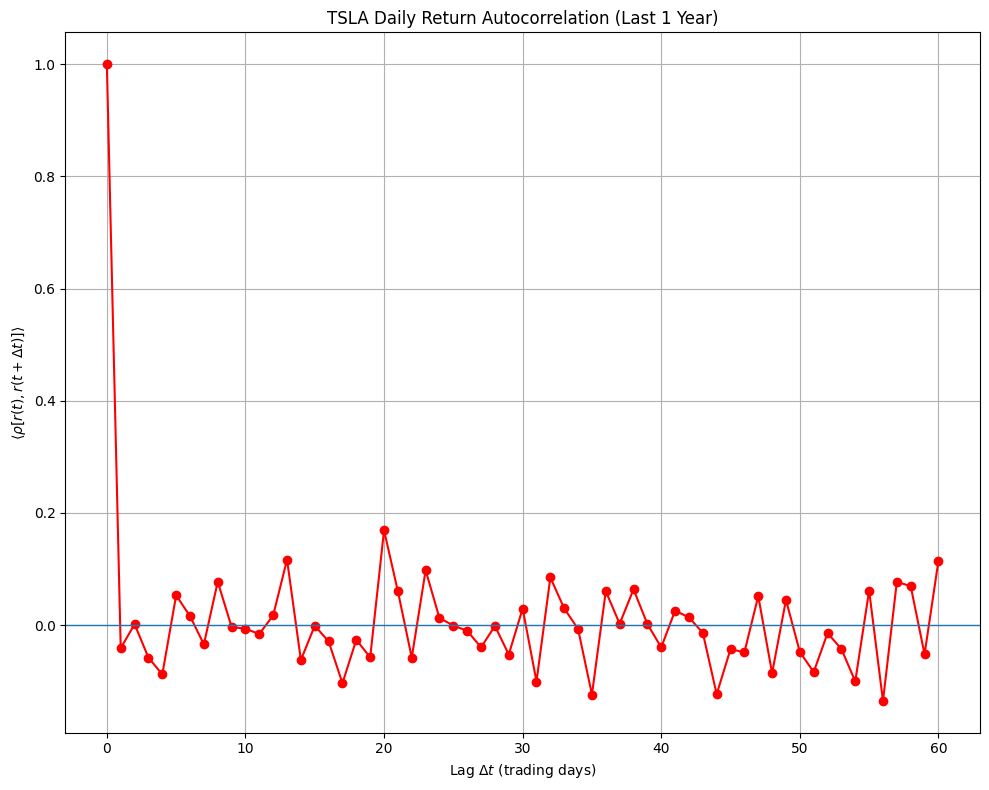

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Parameters

ticker = "TSLA"
max_lag = 60  # trading days

# Download data

data = yf.download(ticker, period="1y", interval="1d", progress=False)

prices = data["Close"].squeeze()


returns = np.log(prices / prices.shift(1)).dropna()

# -----------------------------
# Autocorrelation function

lags = np.arange(0, max_lag + 1)
acf = np.zeros(len(lags))

for i, lag in enumerate(lags):
    if lag == 0:
        acf[i] = np.corrcoef(returns, returns)[0, 1]
    else:
        acf[i] = np.corrcoef(returns[:-lag], returns[lag:])[0, 1]


plt.figure(figsize=(10, 8))
plt.plot(lags, acf, color="red", marker="o")
plt.axhline(0, linewidth=1)
plt.xlabel(r"Lag $\Delta t$ (trading days)")
plt.ylabel(r"$\langle \rho[r(t), r(t+\Delta t)] \rangle$")
plt.title("TSLA Daily Return Autocorrelation (Last 1 Year)")
plt.grid(True)
plt.tight_layout()
plt.show()



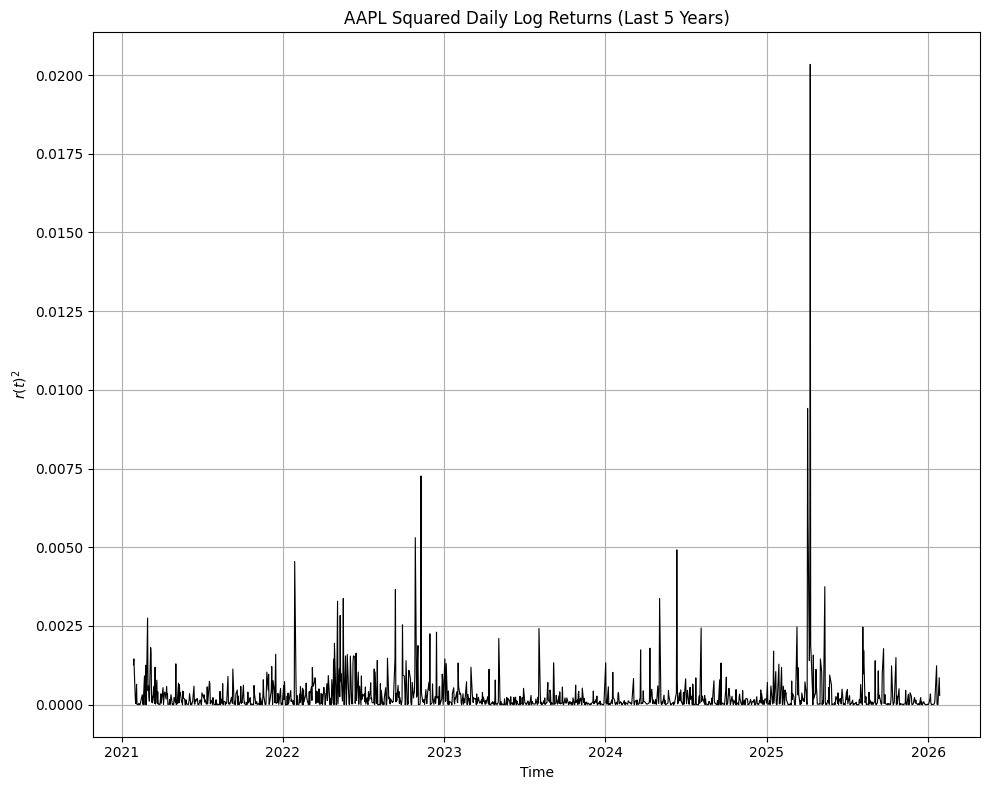

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# Parameters

ticker = "AAPL"
period = "5y"

# data

data = yf.download(ticker, period=period, interval="1d", progress=False)

prices = data["Close"].squeeze()


# Log returns

returns = np.log(prices / prices.shift(1)).dropna()

# Squared returns

squared_returns = returns ** 2


plt.figure(figsize=(10, 8))
plt.plot(squared_returns.index, squared_returns.values, color="black", linewidth=0.8)
plt.xlabel("Time")
plt.ylabel(r"$r(t)^2$")
plt.title("AAPL Squared Daily Log Returns (Last 5 Years)")
plt.grid(True)
plt.tight_layout()
plt.show()


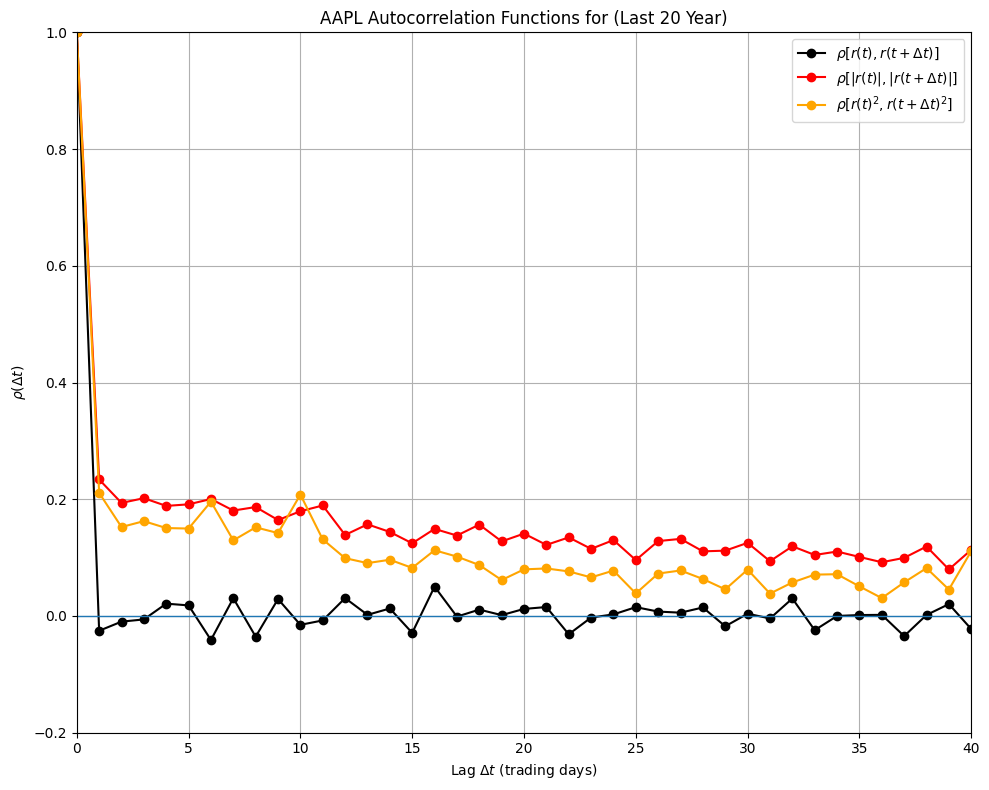

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# Parameters

ticker = "AAPL"
period = "20y"
max_lag = 40  # trading days

# data 

data = yf.download(ticker, period=period, interval="1d", progress=False)
prices = data["Close"].squeeze()

# Log returns

returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)
sq_returns = returns ** 2


# Autocorrelation including lag 0

lags = np.arange(0, max_lag + 1)

acf_r = np.zeros(len(lags))
acf_abs = np.zeros(len(lags))
acf_sq = np.zeros(len(lags))

for i, lag in enumerate(lags):
    if lag == 0:
        acf_r[i] = np.corrcoef(returns, returns)[0, 1]
        acf_abs[i] = np.corrcoef(abs_returns, abs_returns)[0, 1]
        acf_sq[i] = np.corrcoef(sq_returns, sq_returns)[0, 1]
    else:
        acf_r[i] = np.corrcoef(returns[:-lag], returns[lag:])[0, 1]
        acf_abs[i] = np.corrcoef(abs_returns[:-lag], abs_returns[lag:])[0, 1]
        acf_sq[i] = np.corrcoef(sq_returns[:-lag], sq_returns[lag:])[0, 1]


plt.figure(figsize=(10, 8))

plt.plot(lags, acf_r, marker="o", label=r"$\rho[r(t), r(t+\Delta t)]$", color="Black")
plt.plot(lags, acf_abs, marker="o", label=r"$\rho[|r(t)|, |r(t+\Delta t)|]$", color="Red")
plt.plot(lags, acf_sq, marker="o", label=r"$\rho[r(t)^2, r(t+\Delta t)^2]$", color="Orange")

plt.axhline(0, linewidth=1)
plt.xlabel(r"Lag $\Delta t$ (trading days)")
plt.ylabel(r"$\rho(\Delta t)$")
plt.title("AAPL Autocorrelation Functions for (Last 20 Year)")
plt.legend()
plt.grid(True)
plt.xlim(0,40)
plt.ylim(-0.2,1.0)
plt.tight_layout()
plt.show()


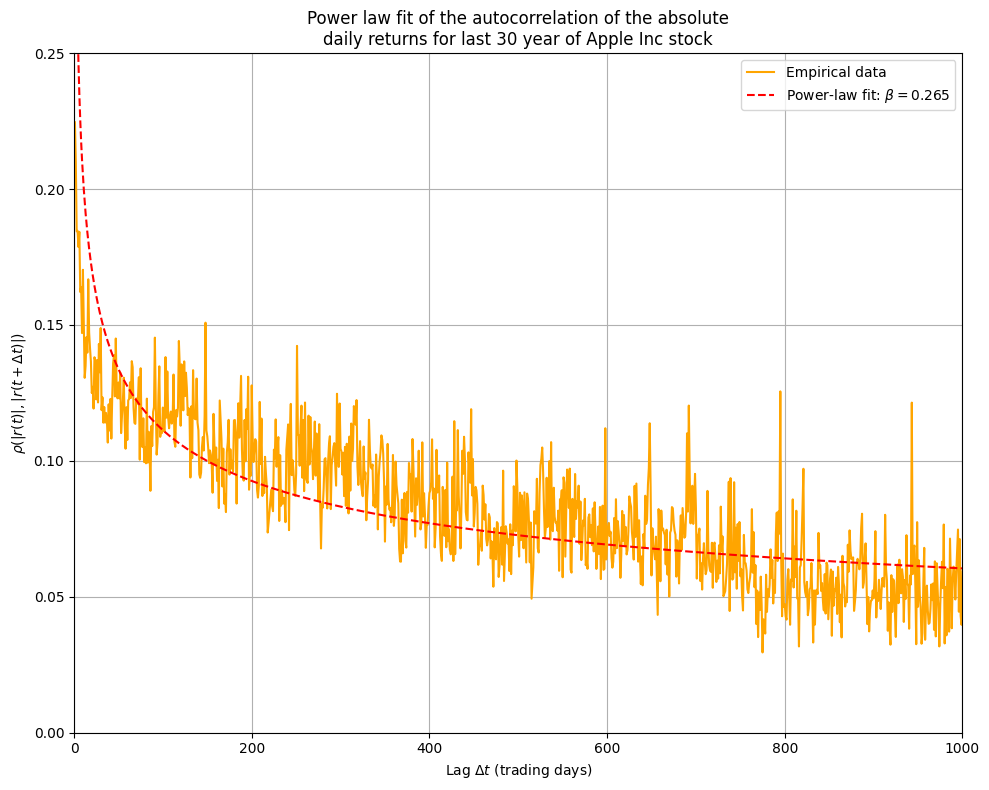

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress


# Parameters

ticker = "AAPL"
period = "30y"
max_lag = 1000

# data

data = yf.download(ticker, period=period, interval="1d", progress=False)
prices = data["Close"].squeeze()

# Log returns

returns = np.log(prices / prices.shift(1)).dropna()
abs_returns = np.abs(returns)

# Autocorrelation of |r(t)|

lags = np.arange(1, max_lag + 1)
acf_abs = np.zeros(len(lags))

for i, lag in enumerate(lags):
    acf_abs[i] = np.corrcoef(
        abs_returns[:-lag],
        abs_returns[lag:]
    )[0, 1]

# Keep only positive correlations for log-log fit
mask = acf_abs > 0
lags_fit = lags[mask]
acf_fit = acf_abs[mask]

# power-law fitting

log_lags = np.log(lags_fit)
log_acf = np.log(acf_fit)

slope, intercept, _, _, _ = linregress(log_lags, log_acf)
beta = -slope

acf_powerlaw = np.exp(intercept) * lags ** (-beta)


plt.figure(figsize=(10, 8))

plt.plot(lags, acf_abs, label="Empirical data", color="Orange")
plt.plot(
    lags,
    acf_powerlaw,
    linestyle="--",
    label=fr"Power-law fit: $\beta = {beta:.3f}$",
    color="Red"
)

plt.xlim(0, 1000)
plt.ylim(0, 0.25)

plt.xlabel(r"Lag $\Delta t$ (trading days)")
plt.ylabel(r"$\rho(|r(t)|, |r(t+\Delta t)|)$")
plt.title(
    "Power law fit of the autocorrelation of the absolute\n"
    "daily returns for last 30 year of Apple Inc stock"
)

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()


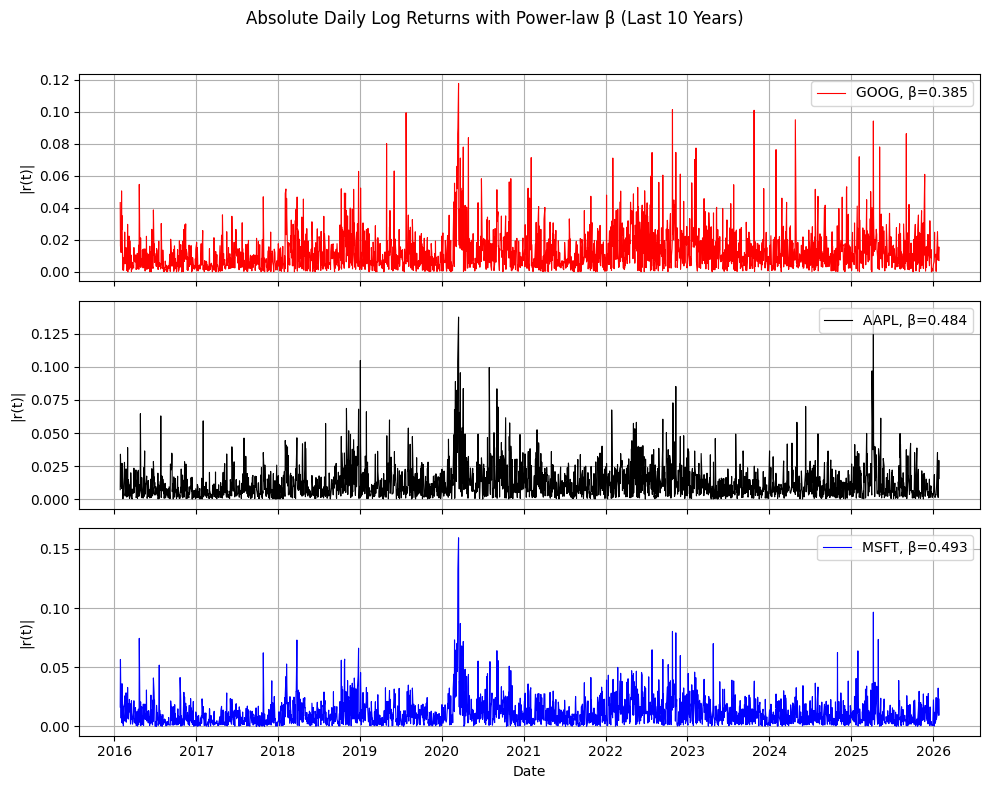

In [ ]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

tickers = ["GOOG", "AAPL", "MSFT"]
colors = ["Red", "black", "blue"]
period = "10y"
max_lag = 1000  # for power-law fit


fig, axes = plt.subplots(len(tickers), 1, figsize=(10, 8), sharex=True)

for ax, ticker, color in zip(axes, tickers, colors):
    #  data
    data = yf.download(ticker, period=period, interval="1d", progress=False)
    prices = data["Close"].squeeze()
    
    # daily log returns
    returns = np.log(prices / prices.shift(1)).dropna()
    abs_returns = np.abs(returns)
    
    # Compute autocorrelation of |r(t)| for power-law fitting
    lags = np.arange(1, max_lag + 1)
    acf_abs = np.zeros(len(lags))
    for i, lag in enumerate(lags):
        acf_abs[i] = np.corrcoef(abs_returns[:-lag], abs_returns[lag:])[0, 1]
    
    # Only positive correlations for log-log fit
    mask = acf_abs > 0
    lags_fit = lags[mask]
    acf_fit = acf_abs[mask]
    
    # Power-law fit
    log_lags = np.log(lags_fit)
    log_acf = np.log(acf_fit)
    slope, intercept, _, _, _ = linregress(log_lags, log_acf)
    beta = -slope
    
    # Plot absolute returns
    ax.plot(abs_returns.index, abs_returns.values, color=color, linewidth=0.8,
            label=fr"{ticker}, β={beta:.3f}")
    
    ax.set_ylabel(r"|r(t)|")
    ax.legend(loc="upper right")
    ax.grid(True)

axes[-1].set_xlabel("Date")
plt.suptitle("Absolute Daily Log Returns with Power-law β (Last 10 Years)")
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


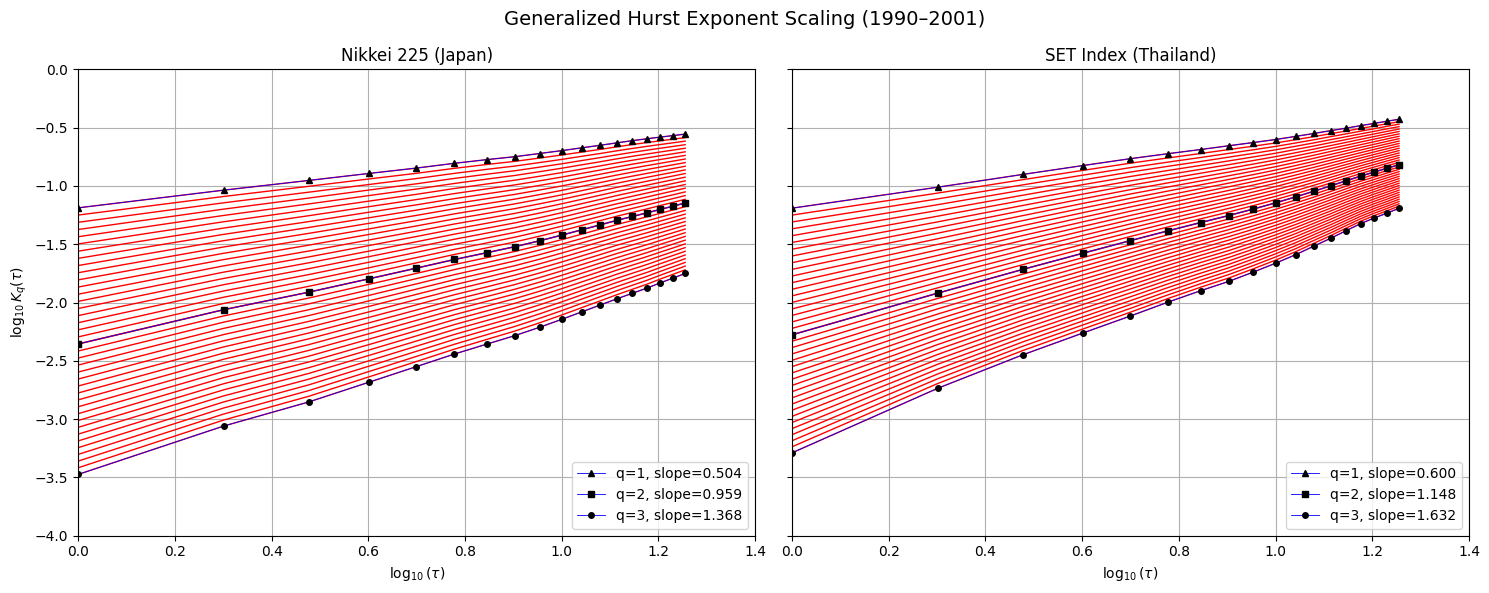

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

taus = np.arange(1, 19)
start = "1990-01-01"
end   = "2001-12-31"

# q ranges
q_low  = np.linspace(1.0, 2.0, 20)
q_high = np.linspace(2.0, 3.0, 20)

# highlight qs
q_highlight = [1, 2, 3]

# highlight color (normalized RGB)
highlight_color = (225/225, 221/225, 187/225)

markets = {
    "Nikkei 225 (Japan)": "^N225",
    "SET Index (Thailand)": "^SET.BK"
}

marker_map = {
    1: "^",   # triangle
    2: "s",   # square
    3: "o"   # circle
}

# axis ranges
X_LIM = (0, 1.4)
Y_LIM = (-4, 0)

# GHE estimator

def generalized_hurst_Kq(log_prices, q, taus):
    X = log_prices.values
    denom = np.mean(np.abs(X) ** q)
    Kq = []

    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)


fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharey=True, sharex=True)

for ax, (title, ticker) in zip(axes, markets.items()):
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna()
    log_prices = np.log10(prices)
    log_prices -= log_prices.mean()

    # --- q in [1,2]
    for q in q_low:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        ax.plot(np.log10(taus), np.log10(Kq),
                color="red", alpha=1, linewidth=1.0)

    # --- q in [2,3]
    for q in q_high:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        ax.plot(np.log10(taus), np.log10(Kq),
                color="red", alpha=1, linewidth=1.0)
        

    # --- highlight q = 1,2,3 + slope
    for q in q_highlight:
        Kq = generalized_hurst_Kq(log_prices, q, taus)
        x = np.log10(taus)
        y = np.log10(Kq)
        
        slope, _, _, _, _ = linregress(x, y)
        
        ax.plot(
        x, y,
        marker=marker_map[q],
        linestyle="-",
        linewidth=0.6,
        markersize=4,
        markerfacecolor="black",
        markeredgecolor="black",
        color="blue",
        label=f"q={q}, slope={slope:.3f}"
    )
        ax.set_title(title)
        ax.set_xlim(X_LIM)
        ax.set_ylim(Y_LIM)
        ax.set_xlabel(r"$\log_{10}(\tau)$")
        ax.grid(True)
        ax.legend()
        
        axes[0].set_ylabel(r"$\log_{10} K_q(\tau)$")
        ax.legend(loc="lower right", frameon=True)

plt.suptitle("Generalized Hurst Exponent Scaling (1990–2001)", fontsize=14)
plt.tight_layout()
plt.show()


[*********************100%***********************]  1 of 1 completed
[*********************100%***********************]  1 of 1 completed


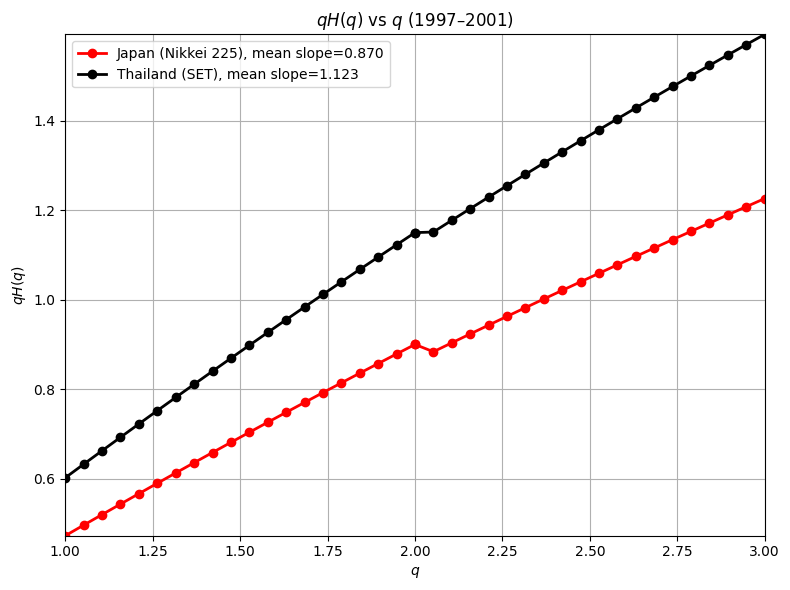

In [ ]:
import numpy as np
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import linregress

# Parameters

start = "1997-01-01"
end   = "2001-12-31"

# q ranges
q_low  = np.linspace(1.0, 2.0, 20)
q_high = np.linspace(2.0, 3.0, 20)
qs = np.concatenate([q_low, q_high])

# tau ranges (q-dependent)
tau_low  = np.arange(1, 19)
tau_high = np.arange(1, 12)

markets = {
    "Japan (Nikkei 225)": ("^N225", "red"),
   "Thailand (SET)": ("^SET.BK", "black")
}

#markets = {
#    "Japan (JPY/USD)": ("JPYUSD=X", "red"),
#    "Thailand (THB/USD)": ("THBUSD=X", "black")
#}

#markets = {
#    "US Treasury 10Y": ("DGS10", "red"),
#    "Eurodollar 1Y": ("USD12MD156N", "black")
#}


# GHE estimator

def generalized_hurst_Kq(log_prices, q, taus):
    X = log_prices.values
    denom = np.mean(np.abs(X) ** q)
    Kq = []

    for tau in taus:
        diff = X[tau:] - X[:-tau]
        Kq.append(np.mean(np.abs(diff) ** q) / denom)

    return np.array(Kq)

# Plot qH(q) vs q

plt.figure(figsize=(8, 6))

all_qHq = []

for label, (ticker, color) in markets.items():
    prices = yf.download(ticker, start=start, end=end)["Close"].dropna()
    log_prices = np.log10(prices)
    log_prices -= log_prices.mean()

    qHq = []

    for q in qs:
        taus = tau_low if q <= 2 else tau_high
        Kq = generalized_hurst_Kq(log_prices, q, taus)

        x = np.log10(taus)
        y = np.log10(Kq)

        slope, _, _, _, _ = linregress(x, y)
        qHq.append(slope)

    qHq = np.array(qHq)
    all_qHq.append(qHq)

    plt.plot(
        qs,
        qHq,
        marker="o",
        linewidth=2,
        color=color,
        label=f"{label}, mean slope={qHq.mean():.3f}"
    )


all_qHq = np.concatenate(all_qHq)

plt.xlim(qs.min(), qs.max())
plt.ylim(all_qHq.min(), all_qHq.max())

plt.xlabel(r"$q$")
plt.ylabel(r"$qH(q)$")
plt.title(r"$qH(q)$ vs $q$ (1997–2001)")
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()
